<a href="https://colab.research.google.com/github/Ashwini4856/BIS_LAB/blob/main/Ant_Colony_optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iteration 20: Best Makespan = 13
Iteration 40: Best Makespan = 13
Iteration 60: Best Makespan = 13
Iteration 80: Best Makespan = 13
Iteration 100: Best Makespan = 13
Iteration 120: Best Makespan = 13
Iteration 140: Best Makespan = 13
Iteration 160: Best Makespan = 13
Iteration 180: Best Makespan = 13
Iteration 200: Best Makespan = 13

========== OPTIMIZED PRODUCTION SCHEDULE ==========
 Job  Operation  Machine  Start  Finish  Duration
   2          1        1      0       2         2
   3          1        2      0       4         4
   1          1        1      2       5         3
   2          2        3      2       3         1
   4          1        3      3       5         2
   2          3        2      4       8         4
   4          2        1      5       9         4
   3          2        3      5       8         3
   1          2        2      8      10         2
   3          3        1      9      11         2
   4          3        2     10      13         3
   1       

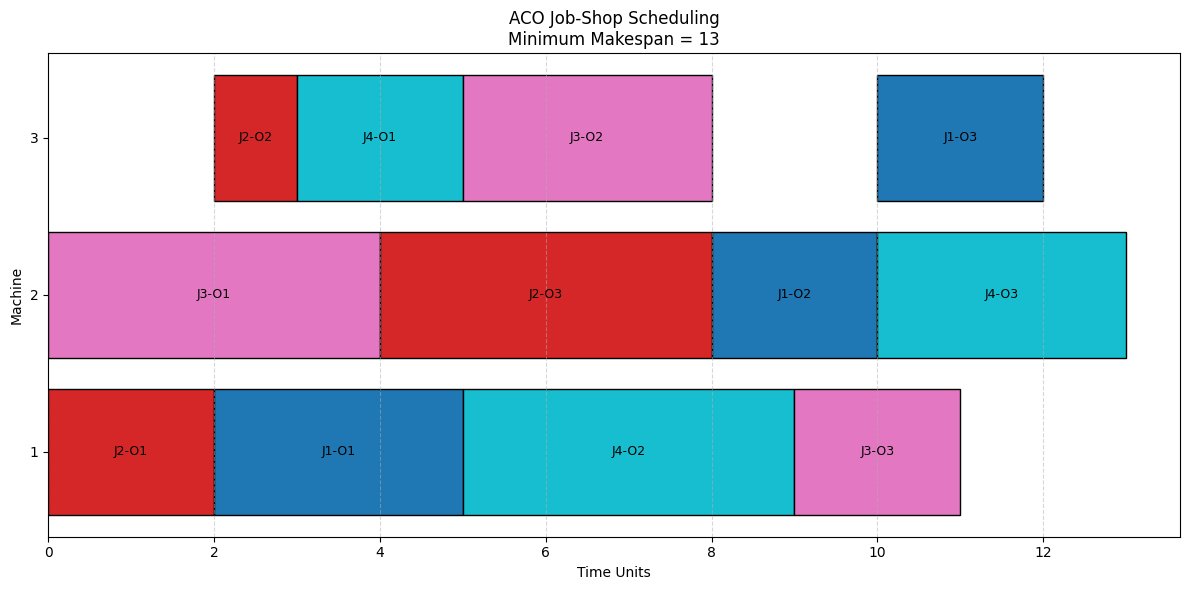

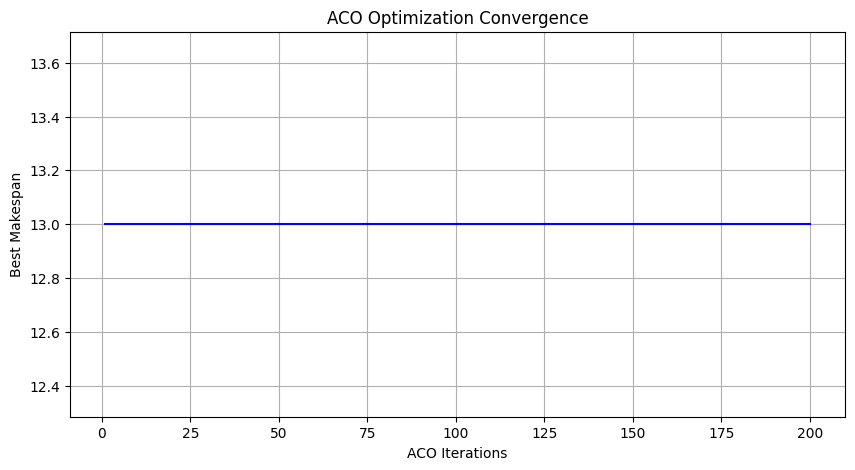

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


jobs = [
    [(0, 3), (1, 2), (2, 2)],
    [(0, 2), (2, 1), (1, 4)],
    [(1, 4), (2, 3), (0, 2)],
    [(2, 2), (0, 4), (1, 3)]
]

num_jobs = len(jobs)
num_machines = 3


NUM_ANTS = 30
ITERATIONS = 200

ALPHA = 1.0
BETA = 2.0
EVAPORATION = 0.1
Q = 100


max_operations = max(len(job) for job in jobs)

pheromone = np.ones((num_jobs, max_operations))

best_makespan = float('inf')
best_schedule = None

convergence = []


def generate_schedule():

    next_operation = [0] * num_jobs

    job_time = [0] * num_jobs

    machine_time = [0] * num_machines

    schedule = []

    total_operations = sum(len(j) for j in jobs)

    while len(schedule) < total_operations:

        available_jobs = []

        probabilities = []

        for j in range(num_jobs):

            if next_operation[j] < len(jobs[j]):

                op = next_operation[j]

                machine, duration = jobs[j][op]

                tau = pheromone[j, op]

                eta = 1.0 / duration

                probability = (tau ** ALPHA) * (eta ** BETA)

                available_jobs.append(j)

                probabilities.append(probability)

        probabilities = np.array(probabilities)

        probabilities /= probabilities.sum()


        selected_job = np.random.choice(
            available_jobs,
            p=probabilities
        )

        op = next_operation[selected_job]

        machine, duration = jobs[selected_job][op]


        start = max(
            job_time[selected_job],
            machine_time[machine]
        )

        finish = start + duration


        schedule.append({
            "Job": selected_job + 1,
            "Operation": op + 1,
            "Machine": machine + 1,
            "Start": start,
            "Finish": finish,
            "Duration": duration
        })


        job_time[selected_job] = finish

        machine_time[machine] = finish

        next_operation[selected_job] += 1

    makespan = max(machine_time)

    return schedule, makespan


for iteration in range(ITERATIONS):

    ant_results = []

    for ant in range(NUM_ANTS):

        schedule, makespan = generate_schedule()

        ant_results.append((schedule, makespan))

        if makespan < best_makespan:

            best_makespan = makespan

            best_schedule = schedule.copy()


    pheromone *= (1 - EVAPORATION)

    for schedule, makespan in ant_results:

        deposit = Q / makespan

        for operation in schedule:

            j = operation["Job"] - 1

            op = operation["Operation"] - 1

            pheromone[j, op] += deposit

    convergence.append(best_makespan)

    if (iteration + 1) % 20 == 0:

        print(
            f"Iteration {iteration + 1}: "
            f"Best Makespan = {best_makespan}"
        )


df = pd.DataFrame(best_schedule)

df = df.sort_values(
    by=["Start", "Machine"]
)

print("\n========== OPTIMIZED PRODUCTION SCHEDULE ==========")

print(df.to_string(index=False))

print("\n===================================================")

print("TOTAL JOBS:", num_jobs)

print("TOTAL MACHINES:", num_machines)

print("TOTAL OPERATIONS:", len(best_schedule))

print("MINIMUM COMPLETION TIME:", best_makespan)

print("===================================================")


print("\nMACHINE UTILIZATION")

for machine in range(num_machines):

    processing_time = sum(
        item["Duration"]
        for item in best_schedule
        if item["Machine"] == machine + 1
    )

    utilization = (
        processing_time / best_makespan
    ) * 100

    print(
        f"Machine {machine + 1}: "
        f"{utilization:.2f}%"
    )


fig, ax = plt.subplots(figsize=(12, 6))

colors = plt.cm.tab10(
    np.linspace(0, 1, num_jobs)
)

for item in best_schedule:

    job = item["Job"]

    machine = item["Machine"]

    start = item["Start"]

    duration = item["Duration"]

    ax.barh(
        machine,
        duration,
        left=start,
        color=colors[job - 1],
        edgecolor="black"
    )

    ax.text(
        start + duration / 2,
        machine,
        f"J{job}-O{item['Operation']}",
        ha="center",
        va="center",
        fontsize=9
    )

ax.set_xlabel("Time Units")

ax.set_ylabel("Machine")

ax.set_title(
    f"ACO Job-Shop Scheduling\n"
    f"Minimum Makespan = {best_makespan}"
)

ax.set_yticks(range(1, num_machines + 1))

ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()

plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    range(1, ITERATIONS + 1),
    convergence,
    color="blue"
)

plt.xlabel("ACO Iterations")

plt.ylabel("Best Makespan")

plt.title("ACO Optimization Convergence")

plt.grid(True)

plt.show()
